In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 1: Problem Defination: We are building a prediction model to see if an individual will get admitted for the fellowship or not.

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,confusion_matrix)

## Data collection and preparation

In [6]:
fellowship_df = pd.read_csv('data/fellowship_data.csv')

In [7]:
fellowship_df.head()

,Name,Gender,Age,City,Graduate,Accepted
0,Kemi Bello,Female,25,Ilorin,Yes,Yes
1,Ngozi Afolabi,Female,31,Ilorin,Yes,Yes
2,Peace Afolabi,Female,30,Kano,Yes,No
3,Ngozi Afolabi,Female,35,Ilorin,Yes,Yes
4,Mariam Bello,Female,20,Ilorin,Yes,Yes


In [8]:
fellowship_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Name      100 non-null    object
 1   Gender    100 non-null    object
 2   Age       100 non-null    int64 
 3   City      100 non-null    object
 4   Graduate  100 non-null    object
 5   Accepted  100 non-null    object
dtypes: int64(1), object(5)
memory usage: 4.8+ KB


In [9]:
fellowship_df.describe()

,Age
count,100.000000
mean,28.030000
std,7.038789
min,16.000000
25%,22.000000
50%,27.500000
75%,33.000000
max,45.000000


In [10]:
fellowship_df['Accepted'].value_counts()

Accepted
Yes    60
No     40
Name: count, dtype: int64

In [11]:
fellowship_df.isnull().sum()

Name        0
Gender      0
Age         0
City        0
Graduate    0
Accepted    0
dtype: int64

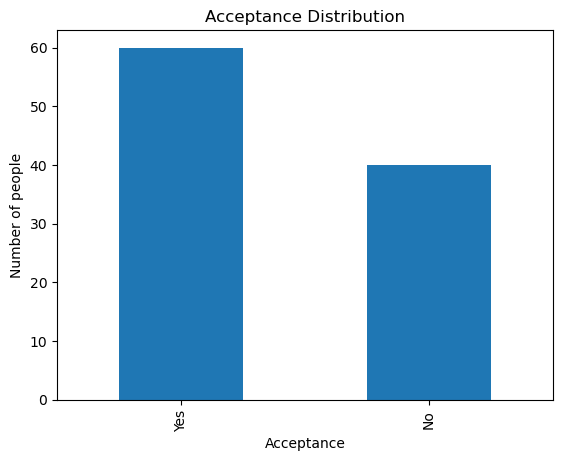

In [12]:
fellowship_df['Accepted'].value_counts().plot(kind='bar')
plt.title('Acceptance Distribution')
plt.xlabel('Acceptance')
plt.ylabel('Number of people')
plt.show()

In [14]:
features = ['Gender','Age','City','Graduate']
target = 'Accepted'

X = fellowship_df[features].copy()
y = fellowship_df[target].copy()


In [15]:
fellowship_df.columns

Index(['Name', 'Gender', 'Age', 'City', 'Graduate', 'Accepted'], dtype='object')

In [16]:
X.head()

,Gender,Age,City,Graduate
0,Female,25,Ilorin,Yes
1,Female,31,Ilorin,Yes
2,Female,30,Kano,Yes
3,Female,35,Ilorin,Yes
4,Female,20,Ilorin,Yes


In [17]:
y.head()

0    Yes
1    Yes
2     No
3    Yes
4    Yes
Name: Accepted, dtype: object

## Convert to categorical data

In [26]:
fellowship_db = pd.read_csv('data/fellowship_data.csv')

In [27]:
fellowship_db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Name      100 non-null    object
 1   Gender    100 non-null    object
 2   Age       100 non-null    int64 
 3   City      100 non-null    object
 4   Graduate  100 non-null    object
 5   Accepted  100 non-null    object
dtypes: int64(1), object(5)
memory usage: 4.8+ KB


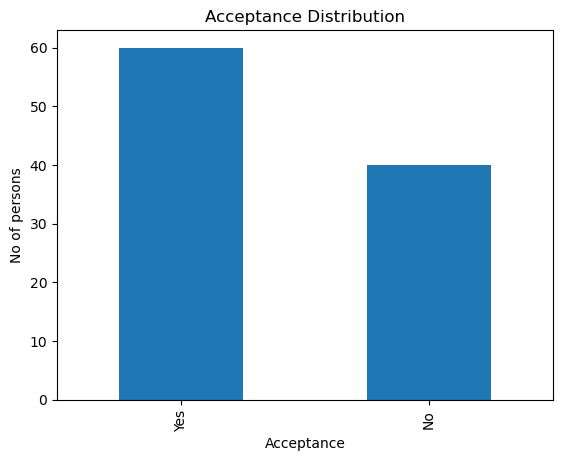

In [33]:
fellowship_db['Accepted'].value_counts().plot(kind='bar')
plt.title('Acceptance Distribution')
plt.xlabel('Acceptance')
plt.ylabel('No of persons')
plt.show()

In [34]:
fellowship_db.columns

Index(['Name', 'Gender', 'Age', 'City', 'Graduate', 'Accepted'], dtype='object')

In [32]:
fellowship_db['City'].value_counts()

City
Ilorin           62
Ibadan            6
Lagos             6
Enugu             5
Abuja             4
Kaduna            4
Sokoto            4
Kano              3
Port Harcourt     2
Benin City        2
Osogbo            2
Name: count, dtype: int64

In [35]:
features = ['Gender','Age','Graduate','City']
target = 'Accepted'

In [36]:
X = fellowship_db[features].copy()
y = fellowship_db[target].copy()

In [37]:
X.head()

,Gender,Age,Graduate,City
0,Female,25,Yes,Ilorin
1,Female,31,Yes,Ilorin
2,Female,30,Yes,Kano
3,Female,35,Yes,Ilorin
4,Female,20,Yes,Ilorin


## Convert to categprical data

In [39]:
X = pd.get_dummies(X, columns=['Gender', 'Age', 'Graduate','City'], drop_first=True)

In [40]:
print(X)

    Gender_Male  Age_17  Age_18  Age_19  Age_20  Age_21  Age_22  Age_23  \
0         False   False   False   False   False   False   False   False   
1         False   False   False   False   False   False   False   False   
2         False   False   False   False   False   False   False   False   
3         False   False   False   False   False   False   False   False   
4         False   False   False   False    True   False   False   False   
..          ...     ...     ...     ...     ...     ...     ...     ...   
95        False   False   False   False   False   False   False   False   
96        False   False   False   False   False    True   False   False   
97         True   False   False   False   False   False   False   False   
98         True   False   False   False   False   False   False   False   
99        False   False   False   False   False   False   False   False   

    Age_24  Age_25  ...  City_Benin City  City_Enugu  City_Ibadan  \
0    False    True  ...       

In [38]:
y.head()

0    Yes
1    Yes
2     No
3    Yes
4    Yes
Name: Accepted, dtype: object

In [43]:
y = pd.get_dummies(y, columns=['Accepted'], drop_first=True)

In [44]:
print(y)

      Yes
0    True
1    True
2   False
3    True
4    True
..    ...
95   True
96   True
97  False
98  False
99   True

[100 rows x 1 columns]


In [45]:
y = y.astype(int)

In [46]:
print(y)

    Yes
0     1
1     1
2     0
3     1
4     1
..  ...
95    1
96    1
97    0
98    0
99    1

[100 rows x 1 columns]


In [47]:
X.head()

,Gender_Male,Age_17,Age_18,Age_19,Age_20,Age_21,Age_22,Age_23,Age_24,Age_25,...,City_Benin City,City_Enugu,City_Ibadan,City_Ilorin,City_Kaduna,City_Kano,City_Lagos,City_Osogbo,City_Port Harcourt,City_Sokoto
0,False,False,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
4,False,False,False,False,True,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [48]:
X = X.astype(int)

In [49]:
X.head()

,Gender_Male,Age_17,Age_18,Age_19,Age_20,Age_21,Age_22,Age_23,Age_24,Age_25,...,City_Benin City,City_Enugu,City_Ibadan,City_Ilorin,City_Kaduna,City_Kano,City_Lagos,City_Osogbo,City_Port Harcourt,City_Sokoto
0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
4,0,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


## Train Test Split

In [64]:
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.2,random_state=42,stratify=y)

In [65]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(80, 38)
(20, 38)
(80, 1)
(20, 1)


## feature scaling

In [56]:
scaler = StandardScaler()

In [69]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Training Logistic regression model

In [70]:
women_AI_model = LogisticRegression(max_iter=1000)
women_AI_model.fit(X_train_scaled,y_train)

C:\Users\MRS LEO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [71]:
model1_predictions= women_AI_model.predict(X_test_scaled)
model1_accuracy = accuracy_score(y_test, model1_predictions)

print('Model1 Accuracy:',  model1_accuracy)

Model1 Accuracy: 1.0


In [72]:
print(confusion_matrix(y_test, model1_predictions))
print(classification_report(y_test, model1_predictions))

[[ 8  0]
 [ 0 12]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        12

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



## Using Decision Tree Classifier

In [74]:
model2 = DecisionTreeClassifier(random_state=42)
model2.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [77]:
model2_predictions = model2.predict(X_test)
model2_accuracy = accuracy_score(y_test, model2_predictions)
print('Model2 Accuracy', model2_accuracy)

Model2 Accuracy 1.0


In [78]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        model1_accuracy * 100,
        model2_accuracy * 100
        
    ]
})
results.round(2)

,Model,Accuracy
0,Logistic Regression,100.0
1,Decision Tree,100.0


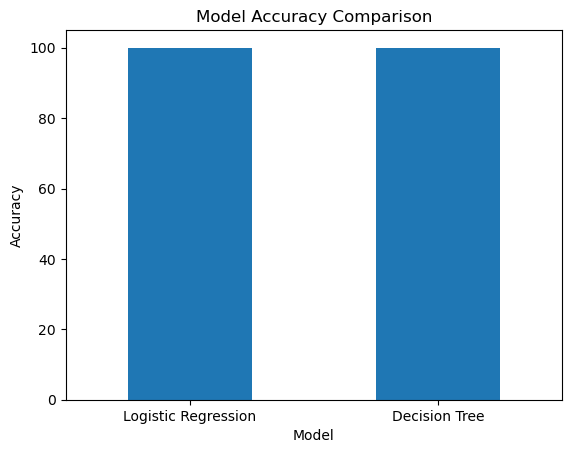

In [79]:
results.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.show()

## Model Deployment

In [ ]:
input_data = [[1,0,70.0, 3, 0, 100]]
model_2.predict(input_data)